# DATA 266 — Homework 11
## CLIP Image–Text Similarity and Zero-Shot CIFAR-10 Classification

**Student:** Nikhil Kanaparthi  
**SID4:** 6441

This notebook completes both required parts:

1. Compare one caption with a balanced collection of CIFAR-10 images using **100 images from each of the 10 classes**.
2. Use CLIP for zero-shot CIFAR-10 classification and report **per-class accuracy** plus a **confusion matrix**.

It also saves the raw scores, figures, findings, reproducibility metadata, and a final submission ZIP. Run the cells in order. Every major section ends with a `PASS` message or an assertion that explains what failed.


## Step 1 — Install the required packages

Google Colab already includes PyTorch and Torchvision. We install a stable Transformers 4.x CLIP interface and the small analysis dependencies. No API key is required.


In [1]:
import subprocess
import sys

packages = [
    "transformers>=4.45,<5",
    "scikit-learn>=1.4",
    "pandas>=2.0",
    "matplotlib>=3.8",
    "seaborn>=0.13",
    "tabulate>=0.9",
]
subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "-U", *packages])
print("STEP 1: PASS — dependencies installed")


STEP 1: PASS — dependencies installed


## Step 2 — Imports, reproducibility, and output folders

SID4 is used as the random seed. The notebook uses a GPU when one is available and safely falls back to CPU.


In [2]:
import gc
import json
import os
import platform
import random
import shutil
import time
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import torch
import torchvision
import transformers
from IPython.display import display, Markdown
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from torchvision.datasets import CIFAR10
from transformers import CLIPModel, CLIPProcessor

STUDENT = "Nikhil Kanaparthi"
SID4 = 6441
SEED = SID4
MODEL_NAME = "openai/clip-vit-base-patch32"
IMAGES_PER_CLASS = 100
NUM_CLASSES = 10
BATCH_SIZE = 64 if torch.cuda.is_available() else 32

ROOT_DIR = Path("/content") if Path("/content").exists() else Path.cwd()
DATA_DIR = ROOT_DIR / "cifar10_data"
OUTPUT_DIR = ROOT_DIR / "HW11_outputs"
FIGURES_DIR = OUTPUT_DIR / "figures"
ZIP_PATH = ROOT_DIR / "HW11_outputs.zip"

if OUTPUT_DIR.exists():
    shutil.rmtree(OUTPUT_DIR)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
try:
    torch.use_deterministic_algorithms(True, warn_only=True)
except Exception:
    pass

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
GPU_NAME = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"
RUN_LOG_LINES = []

def log(message):
    line = f"[{datetime.now(timezone.utc).isoformat()}] {message}"
    RUN_LOG_LINES.append(line)
    print(line)

log(f"Started HW11 for {STUDENT}; SID4={SID4}; seed={SEED}")
log(f"Device={DEVICE}; hardware={GPU_NAME}; batch_size={BATCH_SIZE}")
print("STEP 2: PASS — environment configured")


/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


[2026-11-17T22:20:02.363310+00:00] Started HW11 for Nikhil Kanaparthi; SID4=6441; seed=6441
[2026-11-17T22:20:02.370589+00:00] Device=cuda; hardware=Tesla T4; batch_size=64
STEP 2: PASS — environment configured


## Step 3 — Download CIFAR-10 and select 100 images per class

The official CIFAR-10 test set contains 10 classes. We draw exactly 100 examples per class without replacement using the fixed seed, producing a balanced 1,000-image evaluation set.


In [3]:
cifar10 = CIFAR10(root=str(DATA_DIR), train=False, download=True, transform=None)
CLASS_NAMES = list(cifar10.classes)
assert len(CLASS_NAMES) == NUM_CLASSES

all_targets = np.asarray(cifar10.targets)
rng = np.random.default_rng(SEED)
selected_indices = []

for class_id in range(NUM_CLASSES):
    candidates = np.flatnonzero(all_targets == class_id)
    assert len(candidates) >= IMAGES_PER_CLASS
    chosen = rng.choice(candidates, size=IMAGES_PER_CLASS, replace=False)
    selected_indices.extend(sorted(chosen.tolist()))

selected_records = []
for selection_position, dataset_index in enumerate(selected_indices):
    _, class_id = cifar10[dataset_index]
    selected_records.append({
        "selection_position": selection_position,
        "dataset_index": int(dataset_index),
        "true_class_id": int(class_id),
        "true_class_name": CLASS_NAMES[class_id],
    })

selected_df = pd.DataFrame(selected_records)
class_counts = selected_df["true_class_name"].value_counts().sort_index()
assert len(selected_df) == IMAGES_PER_CLASS * NUM_CLASSES == 1000
assert class_counts.eq(IMAGES_PER_CLASS).all()

selected_df.to_csv(OUTPUT_DIR / "selected_image_manifest.csv", index=False)
display(class_counts.rename("selected_images").to_frame())
log("Selected exactly 100 test images from each CIFAR-10 class")
print("STEP 3: PASS — balanced 1,000-image subset created")


100%|██████████| 170M/170M [12:50<00:00, 221kB/s]


,selected_images
true_class_name,
airplane,100
automobile,100
bird,100
cat,100
deer,100
dog,100
frog,100
horse,100
ship,100


[2026-11-17T22:32:57.745915+00:00] Selected exactly 100 test images from each CIFAR-10 class
STEP 3: PASS — balanced 1,000-image subset created


## Step 4 — Load CLIP

`CLIPProcessor` performs the model-specific image resizing, normalization, and text tokenization. `CLIPModel` produces aligned image and text embeddings.


In [4]:
processor = CLIPProcessor.from_pretrained(MODEL_NAME)
model = CLIPModel.from_pretrained(MODEL_NAME).to(DEVICE)
model.eval()
model.requires_grad_(False)

trainable_parameters = sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)
total_parameters = sum(parameter.numel() for parameter in model.parameters())
assert total_parameters > 0

print("Model:", MODEL_NAME)
print("Device:", DEVICE)
print(f"Parameters: {total_parameters:,}")
print(f"Trainable parameters during evaluation: {trainable_parameters:,}")
print("Training performed: No — zero-shot evaluation only")
log(f"Loaded {MODEL_NAME} with {total_parameters:,} parameters")
print("STEP 4: PASS — CLIP model and processor loaded")


Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.
/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/605M [00:00<?, ?B/s]

Model: openai/clip-vit-base-patch32
Device: cuda
Parameters: 151,277,313
Trainable parameters during evaluation: 0
Training performed: No — zero-shot evaluation only
[2026-11-17T22:33:08.365695+00:00] Loaded openai/clip-vit-base-patch32 with 151,277,313 parameters
STEP 4: PASS — CLIP model and processor loaded


## Step 5 — Preprocess images and extract normalized embeddings

Images are processed in batches to avoid unnecessary memory use. Each embedding is divided by its L2 norm, so the matrix product with a normalized text embedding is cosine similarity.


In [5]:
def l2_normalize(features):
    return features / features.norm(dim=-1, keepdim=True).clamp_min(1e-12)

def encode_images(dataset_indices, batch_size=BATCH_SIZE):
    batches = []
    start_time = time.perf_counter()
    for start in range(0, len(dataset_indices), batch_size):
        batch_indices = dataset_indices[start:start + batch_size]
        images = [cifar10[index][0] for index in batch_indices]
        inputs = processor(images=images, return_tensors="pt")
        pixel_values = inputs["pixel_values"].to(DEVICE)
        with torch.inference_mode():
            features = model.get_image_features(pixel_values=pixel_values)
            features = l2_normalize(features)
        batches.append(features.cpu())
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    elapsed = time.perf_counter() - start_time
    return torch.cat(batches, dim=0), elapsed

image_features, embedding_seconds = encode_images(selected_indices)
assert image_features.shape[0] == len(selected_df)
assert torch.allclose(
    image_features.norm(dim=-1),
    torch.ones(len(image_features)),
    atol=1e-4,
)

EMBEDDING_DIMENSION = int(image_features.shape[1])
print("Image embedding matrix:", tuple(image_features.shape))
print(f"Embedding time: {embedding_seconds:.2f} seconds")
print(f"Throughput: {len(selected_df) / embedding_seconds:.2f} images/second")
log(f"Encoded and normalized 1,000 images in {embedding_seconds:.3f} seconds")
print("STEP 5: PASS — image embeddings extracted and normalized")


model.safetensors:   0%|          | 0.00/605M [00:00<?, ?B/s]

Image embedding matrix: (1000, 512)
Embedding time: 8.13 seconds
Throughput: 123.02 images/second
[2026-11-17T22:33:16.520337+00:00] Encoded and normalized 1,000 images in 8.129 seconds
STEP 5: PASS — image embeddings extracted and normalized


# Part A — Caption-to-image similarity

## Step 6 — Define and encode the caption

SID4 selects class index `6441 mod 10 = 1`, which is CIFAR-10's **automobile** class. The caption is fixed before looking at the results.


In [6]:
TARGET_CLASS_ID = SID4 % NUM_CLASSES
TARGET_CLASS_NAME = CLASS_NAMES[TARGET_CLASS_ID]
CAPTION = "a clear color photograph of a car"

text_inputs = processor(text=[CAPTION], return_tensors="pt", padding=True)
text_inputs = {name: tensor.to(DEVICE) for name, tensor in text_inputs.items()}
with torch.inference_mode():
    caption_feature = model.get_text_features(**text_inputs)
    caption_feature = l2_normalize(caption_feature).cpu()

assert caption_feature.shape == (1, EMBEDDING_DIMENSION)
assert torch.allclose(caption_feature.norm(dim=-1), torch.ones(1), atol=1e-4)
print("Target class:", TARGET_CLASS_NAME)
print("Caption:", CAPTION)
print("Caption embedding shape:", tuple(caption_feature.shape))
log(f"Encoded caption for target class {TARGET_CLASS_NAME!r}: {CAPTION!r}")
print("STEP 6: PASS — caption defined and normalized embedding extracted")


Target class: automobile
Caption: a clear color photograph of a car
Caption embedding shape: (1, 512)
[2026-11-17T22:33:16.659622+00:00] Encoded caption for target class 'automobile': 'a clear color photograph of a car'
STEP 6: PASS — caption defined and normalized embedding extracted


## Step 7 — Compute caption similarity scores

A normalized image vector dotted with the normalized caption vector gives cosine similarity. We save every score and summarize the distribution separately for all 10 classes.


In [7]:
caption_similarities = (image_features @ caption_feature.T).squeeze(1).numpy()

similarity_df = selected_df.copy()
similarity_df["caption"] = CAPTION
similarity_df["cosine_similarity"] = caption_similarities
similarity_df["global_similarity_rank"] = (
    similarity_df["cosine_similarity"].rank(method="first", ascending=False).astype(int)
)
similarity_df["is_target_class"] = similarity_df["true_class_id"] == TARGET_CLASS_ID
similarity_df.to_csv(OUTPUT_DIR / "caption_image_similarity_scores.csv", index=False)

class_similarity_summary_df = (
    similarity_df.groupby(["true_class_id", "true_class_name"], as_index=False)
    .agg(
        image_count=("cosine_similarity", "size"),
        mean_similarity=("cosine_similarity", "mean"),
        std_similarity=("cosine_similarity", "std"),
        min_similarity=("cosine_similarity", "min"),
        median_similarity=("cosine_similarity", "median"),
        max_similarity=("cosine_similarity", "max"),
    )
    .sort_values("mean_similarity", ascending=False)
    .reset_index(drop=True)
)
class_similarity_summary_df.to_csv(OUTPUT_DIR / "caption_similarity_by_class.csv", index=False)
display(class_similarity_summary_df.round(4))

highest_mean_class = class_similarity_summary_df.iloc[0]["true_class_name"]
target_mean = float(
    class_similarity_summary_df.loc[
        class_similarity_summary_df["true_class_id"] == TARGET_CLASS_ID,
        "mean_similarity",
    ].iloc[0]
)
non_target_mean = float(similarity_df.loc[~similarity_df["is_target_class"], "cosine_similarity"].mean())
top_20_target_fraction = float(
    similarity_df.nsmallest(20, "global_similarity_rank")["is_target_class"].mean()
)

print("Highest mean-similarity class:", highest_mean_class)
print(f"Target-class mean similarity: {target_mean:.4f}")
print(f"Non-target mean similarity: {non_target_mean:.4f}")
print(f"Target-class fraction in top 20 images: {top_20_target_fraction:.1%}")
log("Computed and saved all 1,000 caption–image cosine similarities")
print("STEP 7: PASS — similarity scores computed and summarized")


,true_class_id,true_class_name,image_count,mean_similarity,std_similarity,min_similarity,median_similarity,max_similarity
0,1,automobile,100,0.2518,0.0118,0.2198,0.2512,0.2831
1,9,truck,100,0.2141,0.0135,0.1768,0.2127,0.2591
2,6,frog,100,0.2012,0.0114,0.1739,0.2012,0.2264
3,0,airplane,100,0.1936,0.0169,0.1507,0.1931,0.2469
4,3,cat,100,0.1928,0.0109,0.1657,0.1935,0.2238
5,4,deer,100,0.1927,0.0105,0.1625,0.1927,0.2184
6,2,bird,100,0.1917,0.0127,0.1624,0.1913,0.2331
7,5,dog,100,0.1886,0.0122,0.1579,0.1892,0.2222
8,8,ship,100,0.1880,0.0177,0.1527,0.1864,0.2551
9,7,horse,100,0.1858,0.0106,0.1521,0.1861,0.2090


Highest mean-similarity class: automobile
Target-class mean similarity: 0.2518
Non-target mean similarity: 0.1943
Target-class fraction in top 20 images: 100.0%
[2026-11-17T22:33:16.720662+00:00] Computed and saved all 1,000 caption–image cosine similarities
STEP 7: PASS — similarity scores computed and summarized


## Step 8 — Visualize similarity distributions and scored images

The first figure compares all 100 scores from every class. The next two figures show the highest-scoring image from each class and the ten highest-scoring images overall, with the computed score printed beside each image.


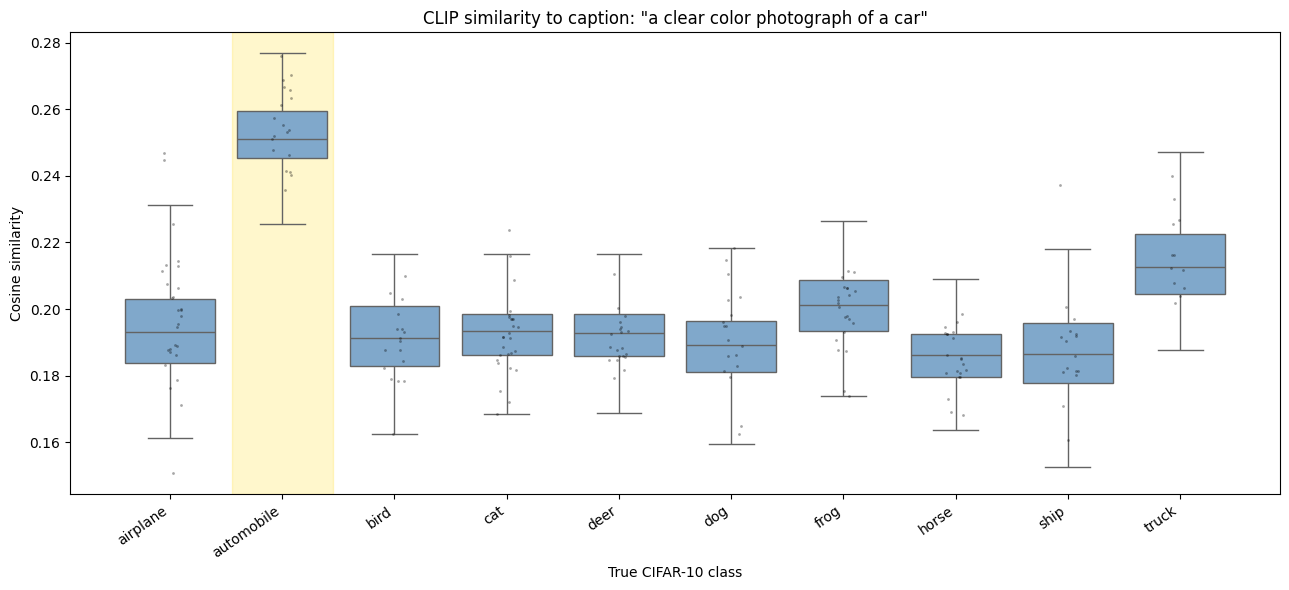

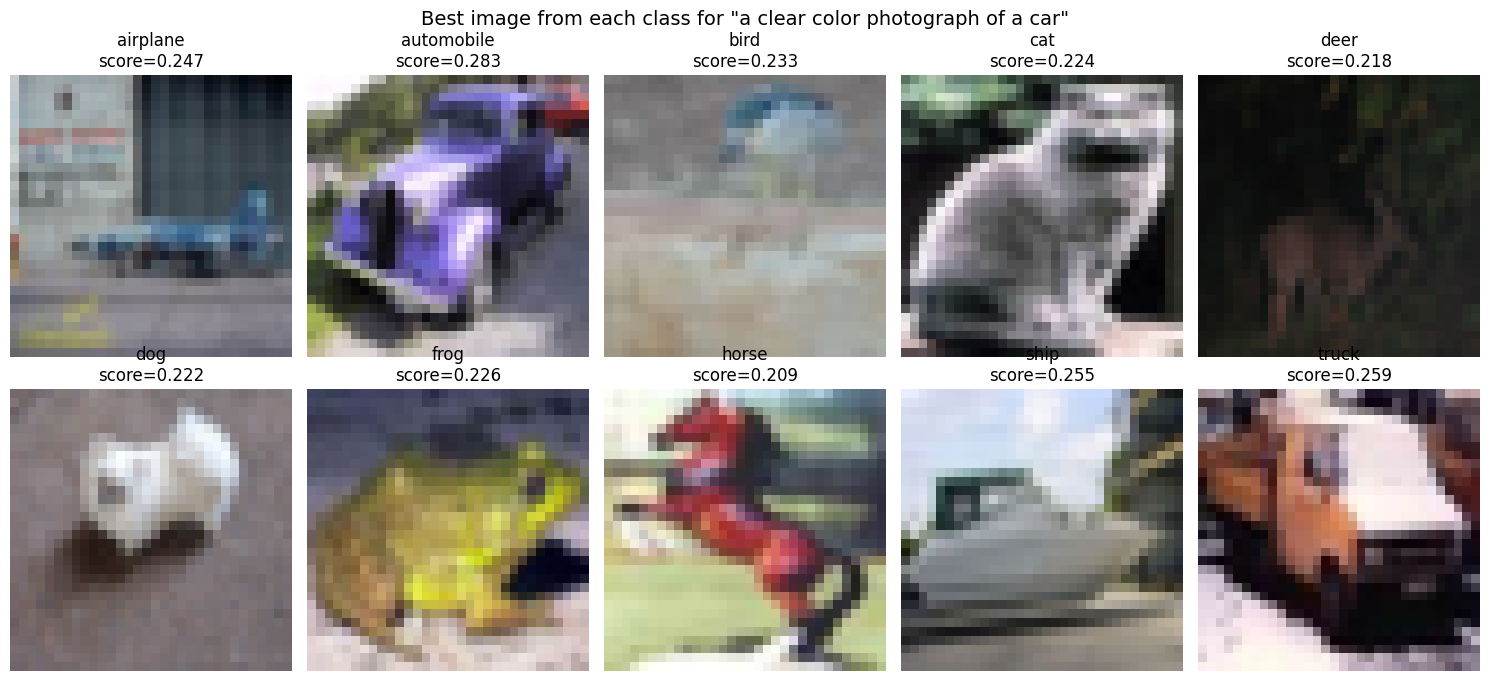

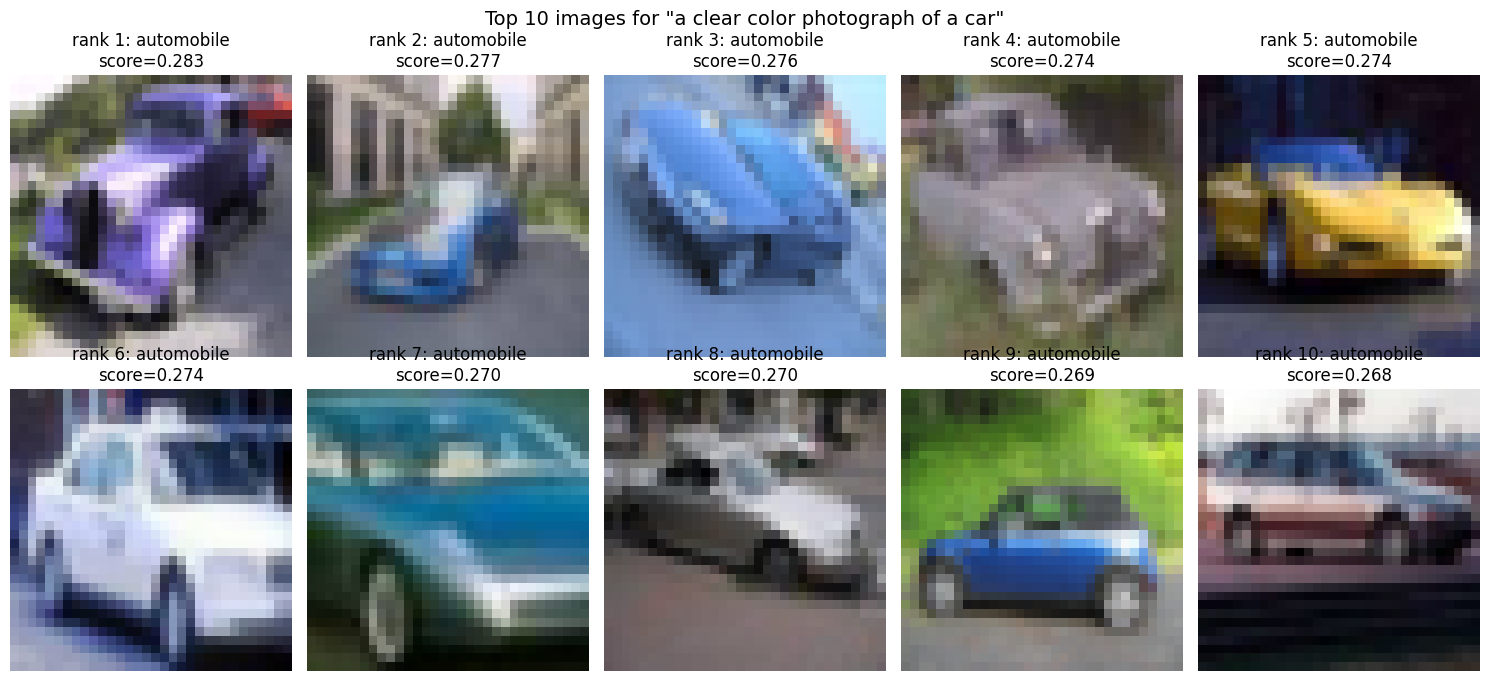

STEP 8: PASS — similarity results visualized with scores


In [8]:
plt.figure(figsize=(13, 6))
sns.boxplot(
    data=similarity_df,
    x="true_class_name",
    y="cosine_similarity",
    order=CLASS_NAMES,
    color="#73a9d8",
    showfliers=False,
)
sns.stripplot(
    data=similarity_df.sample(frac=0.20, random_state=SEED),
    x="true_class_name",
    y="cosine_similarity",
    order=CLASS_NAMES,
    color="black",
    alpha=0.35,
    size=2,
)
plt.axvspan(TARGET_CLASS_ID - 0.45, TARGET_CLASS_ID + 0.45, color="gold", alpha=0.20)
plt.xticks(rotation=35, ha="right")
plt.xlabel("True CIFAR-10 class")
plt.ylabel("Cosine similarity")
plt.title(f'CLIP similarity to caption: "{CAPTION}"')
plt.tight_layout()
plt.savefig(FIGURES_DIR / "caption_similarity_distributions.png", dpi=180)
plt.show()

best_per_class = (
    similarity_df.sort_values("cosine_similarity", ascending=False)
    .groupby("true_class_id", as_index=False)
    .first()
    .sort_values("true_class_id")
)
fig, axes = plt.subplots(2, 5, figsize=(15, 7))
for axis, row in zip(axes.ravel(), best_per_class.itertuples(index=False)):
    image, _ = cifar10[row.dataset_index]
    axis.imshow(image)
    axis.set_title(f"{row.true_class_name}\nscore={row.cosine_similarity:.3f}")
    axis.axis("off")
fig.suptitle(f'Best image from each class for "{CAPTION}"', fontsize=14)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "best_image_per_class_with_scores.png", dpi=180)
plt.show()

top_ten = similarity_df.nsmallest(10, "global_similarity_rank")
fig, axes = plt.subplots(2, 5, figsize=(15, 7))
for axis, row in zip(axes.ravel(), top_ten.itertuples(index=False)):
    image, _ = cifar10[row.dataset_index]
    axis.imshow(image)
    axis.set_title(
        f"rank {row.global_similarity_rank}: {row.true_class_name}\nscore={row.cosine_similarity:.3f}"
    )
    axis.axis("off")
fig.suptitle(f'Top 10 images for "{CAPTION}"', fontsize=14)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "top_10_caption_matches.png", dpi=180)
plt.show()

print("STEP 8: PASS — similarity results visualized with scores")


# Part B — CLIP zero-shot CIFAR-10 classification

## Step 9 — Create text prototypes for the ten classes

No CIFAR-10 image is used to train or update CLIP. For each class, five prompt templates are encoded and averaged into one normalized text prototype. Prompt ensembling reduces dependence on one wording while remaining fully zero-shot.


In [9]:
OBJECT_PHRASES = {
    "airplane": "an airplane",
    "automobile": "a car",
    "bird": "a bird",
    "cat": "a cat",
    "deer": "a deer",
    "dog": "a dog",
    "frog": "a frog",
    "horse": "a horse",
    "ship": "a ship",
    "truck": "a truck",
}
PROMPT_TEMPLATES = [
    "a photo of {}",
    "a clear photo of {}",
    "a close-up photo of {}",
    "a small photo of {}",
    "a color image of {}",
]

class_text_features = []
prompt_rows = []
for class_id, class_name in enumerate(CLASS_NAMES):
    prompts = [template.format(OBJECT_PHRASES[class_name]) for template in PROMPT_TEMPLATES]
    text_batch = processor(text=prompts, return_tensors="pt", padding=True)
    text_batch = {name: tensor.to(DEVICE) for name, tensor in text_batch.items()}
    with torch.inference_mode():
        features = model.get_text_features(**text_batch)
        features = l2_normalize(features)
        prototype = l2_normalize(features.mean(dim=0, keepdim=True))
    class_text_features.append(prototype.cpu())
    for template_id, prompt in enumerate(prompts):
        prompt_rows.append({
            "class_id": class_id,
            "class_name": class_name,
            "template_id": template_id,
            "prompt": prompt,
        })

class_text_features = torch.cat(class_text_features, dim=0)
class_prompts_df = pd.DataFrame(prompt_rows)
class_prompts_df.to_csv(OUTPUT_DIR / "zero_shot_prompts.csv", index=False)

assert class_text_features.shape == (NUM_CLASSES, EMBEDDING_DIMENSION)
assert torch.allclose(class_text_features.norm(dim=-1), torch.ones(NUM_CLASSES), atol=1e-4)
display(class_prompts_df.groupby("class_name")["prompt"].apply(list).to_frame())
log("Created normalized zero-shot text prototypes using five prompts per class")
print("STEP 9: PASS — class text embeddings created")


,prompt
class_name,
airplane,"[a photo of an airplane, a clear photo of an a..."
automobile,"[a photo of a car, a clear photo of a car, a c..."
bird,"[a photo of a bird, a clear photo of a bird, a..."
cat,"[a photo of a cat, a clear photo of a cat, a c..."
deer,"[a photo of a deer, a clear photo of a deer, a..."
dog,"[a photo of a dog, a clear photo of a dog, a c..."
frog,"[a photo of a frog, a clear photo of a frog, a..."
horse,"[a photo of a horse, a clear photo of a horse,..."
ship,"[a photo of a ship, a clear photo of a ship, a..."


[2026-11-17T22:33:19.438371+00:00] Created normalized zero-shot text prototypes using five prompts per class
STEP 9: PASS — class text embeddings created


## Step 10 — Perform zero-shot classification

Each image is assigned to the class with the largest image–text cosine similarity. CLIP's learned logit scale is used only to convert similarities into confidence values; it does not change the winning class.


In [10]:
cosine_logits = image_features @ class_text_features.T
logit_scale = float(model.logit_scale.exp().detach().cpu().clamp(max=100.0))
probabilities = torch.softmax(cosine_logits * logit_scale, dim=1)
predicted_ids = probabilities.argmax(dim=1).numpy()
confidence = probabilities.max(dim=1).values.numpy()
true_ids = selected_df["true_class_id"].to_numpy()

predictions_df = selected_df.copy()
predictions_df["predicted_class_id"] = predicted_ids
predictions_df["predicted_class_name"] = [CLASS_NAMES[index] for index in predicted_ids]
predictions_df["confidence"] = confidence
predictions_df["correct"] = predictions_df["predicted_class_id"] == predictions_df["true_class_id"]
predictions_df.to_csv(OUTPUT_DIR / "zero_shot_predictions.csv", index=False)

overall_accuracy = float(accuracy_score(true_ids, predicted_ids))
print(f"Overall zero-shot accuracy: {overall_accuracy:.2%}")
display(predictions_df.head())
log(f"Completed zero-shot classification; overall_accuracy={overall_accuracy:.6f}")
print("STEP 10: PASS — all 1,000 images classified")


Overall zero-shot accuracy: 89.50%


,selection_position,dataset_index,true_class_id,true_class_name,predicted_class_id,predicted_class_name,confidence,correct
0,0,90,0,airplane,0,airplane,0.946587,True
1,1,313,0,airplane,2,bird,0.294639,False
2,2,499,0,airplane,0,airplane,0.539879,True
3,3,602,0,airplane,0,airplane,0.969636,True
4,4,814,0,airplane,9,truck,0.577123,False


[2026-11-17T22:33:19.555036+00:00] Completed zero-shot classification; overall_accuracy=0.895000
STEP 10: PASS — all 1,000 images classified


## Step 11 — Per-class accuracy and classification report

Because the subset has exactly 100 images per class, each per-class accuracy is also the number of correct images divided by 100.


,class_id,class_name,correct,total,accuracy
0,0,airplane,93,100,93.00%
1,1,automobile,94,100,94.00%
2,2,bird,87,100,87.00%
3,3,cat,89,100,89.00%
4,4,deer,79,100,79.00%
5,5,dog,90,100,90.00%
6,6,frog,76,100,76.00%
7,7,horse,98,100,98.00%
8,8,ship,92,100,92.00%
9,9,truck,97,100,97.00%


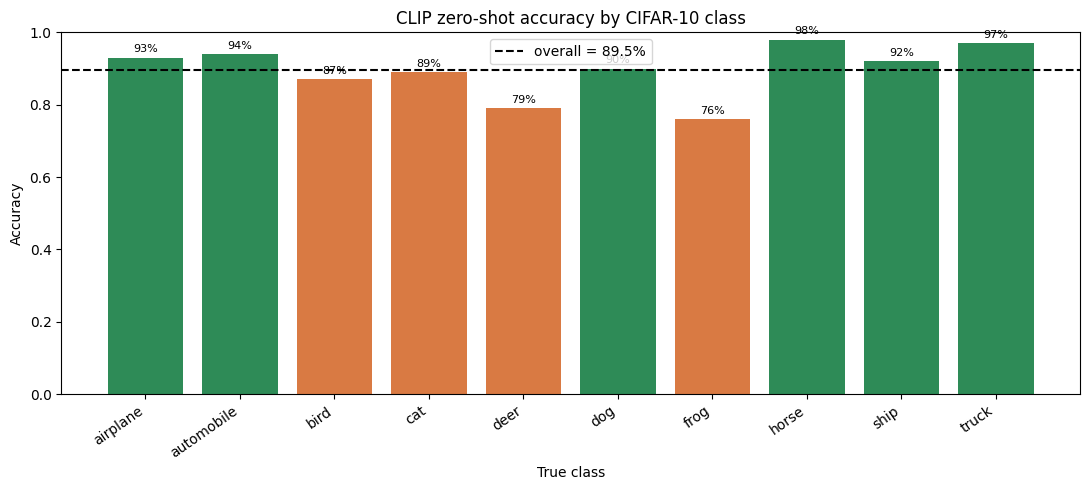

[2026-11-17T22:33:20.043788+00:00] Calculated and saved per-class accuracy and classification report
STEP 11: PASS — per-class accuracy reported


In [11]:
report_dict = classification_report(
    true_ids,
    predicted_ids,
    labels=list(range(NUM_CLASSES)),
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0,
)
classification_report_df = pd.DataFrame(report_dict).T.reset_index(names="label")
classification_report_df.to_csv(OUTPUT_DIR / "classification_report.csv", index=False)

per_class_rows = []
for class_id, class_name in enumerate(CLASS_NAMES):
    class_mask = true_ids == class_id
    correct = int((predicted_ids[class_mask] == class_id).sum())
    total = int(class_mask.sum())
    per_class_rows.append({
        "class_id": class_id,
        "class_name": class_name,
        "correct": correct,
        "total": total,
        "accuracy": correct / total,
    })
per_class_accuracy_df = pd.DataFrame(per_class_rows)
per_class_accuracy_df.to_csv(OUTPUT_DIR / "per_class_accuracy.csv", index=False)
display(per_class_accuracy_df.style.format({"accuracy": "{:.2%}"}))

plt.figure(figsize=(11, 5))
colors = ["#2e8b57" if value >= overall_accuracy else "#d97a43" for value in per_class_accuracy_df["accuracy"]]
bars = plt.bar(per_class_accuracy_df["class_name"], per_class_accuracy_df["accuracy"], color=colors)
plt.axhline(overall_accuracy, color="black", linestyle="--", label=f"overall = {overall_accuracy:.1%}")
plt.ylim(0, 1.0)
plt.ylabel("Accuracy")
plt.xlabel("True class")
plt.title("CLIP zero-shot accuracy by CIFAR-10 class")
plt.xticks(rotation=35, ha="right")
plt.legend()
for bar, value in zip(bars, per_class_accuracy_df["accuracy"]):
    plt.text(bar.get_x() + bar.get_width()/2, value + 0.015, f"{value:.0%}", ha="center", fontsize=8)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "per_class_accuracy.png", dpi=180)
plt.show()

best_class_row = per_class_accuracy_df.sort_values("accuracy", ascending=False).iloc[0]
worst_class_row = per_class_accuracy_df.sort_values("accuracy", ascending=True).iloc[0]
log("Calculated and saved per-class accuracy and classification report")
print("STEP 11: PASS — per-class accuracy reported")


## Step 12 — Confusion matrix

We save both raw counts and row-normalized percentages. Every row in the count matrix sums to 100 because the evaluation subset is balanced.


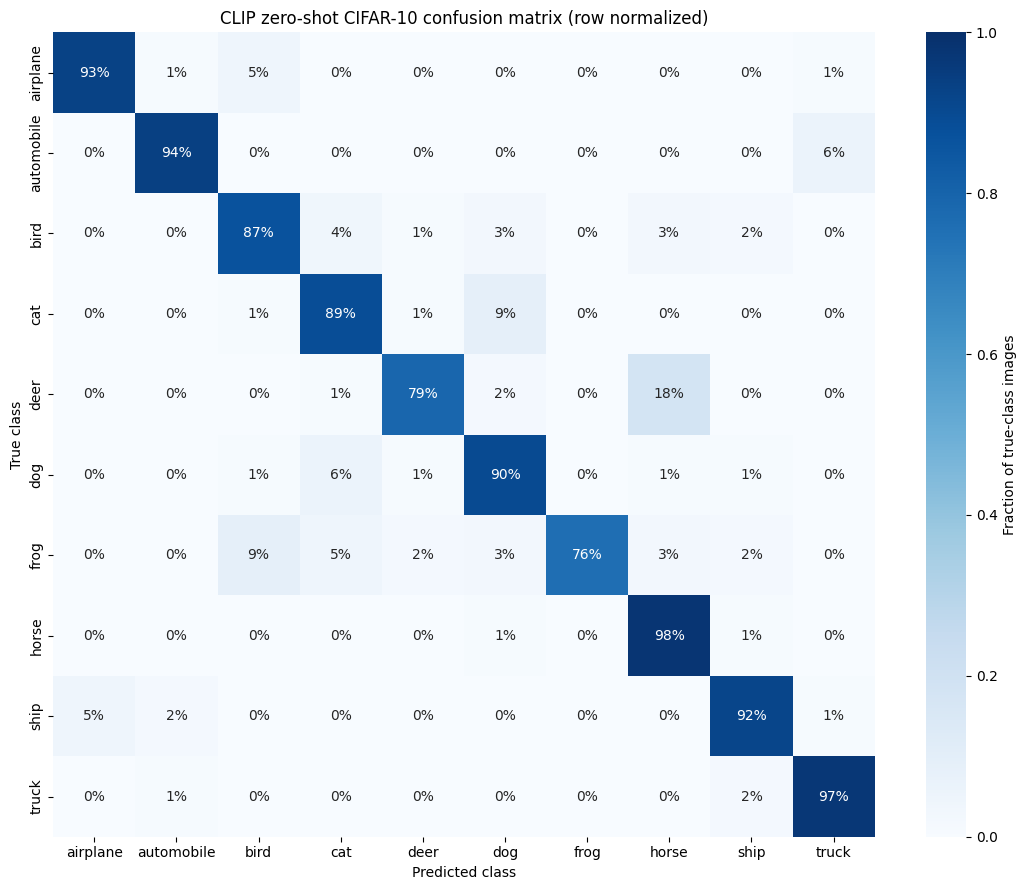

Each row sum: [100, 100, 100, 100, 100, 100, 100, 100, 100, 100]
Largest off-diagonal confusion: deer → horse (18 of 100 images)
[2026-11-17T22:33:20.897787+00:00] Saved confusion matrices; largest confusion=deer → horse (18 of 100 images)
STEP 12: PASS — confusion matrix generated


In [12]:
cm_counts = confusion_matrix(true_ids, predicted_ids, labels=list(range(NUM_CLASSES)))
cm_normalized = cm_counts / cm_counts.sum(axis=1, keepdims=True)

cm_counts_df = pd.DataFrame(cm_counts, index=CLASS_NAMES, columns=CLASS_NAMES)
cm_normalized_df = pd.DataFrame(cm_normalized, index=CLASS_NAMES, columns=CLASS_NAMES)
cm_counts_df.to_csv(OUTPUT_DIR / "confusion_matrix_counts.csv", index_label="true_class")
cm_normalized_df.to_csv(OUTPUT_DIR / "confusion_matrix_normalized.csv", index_label="true_class")

plt.figure(figsize=(11, 9))
sns.heatmap(
    cm_normalized_df,
    annot=True,
    fmt=".0%",
    cmap="Blues",
    vmin=0,
    vmax=1,
    cbar_kws={"label": "Fraction of true-class images"},
)
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.title("CLIP zero-shot CIFAR-10 confusion matrix (row normalized)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "confusion_matrix_normalized.png", dpi=180)
plt.show()

off_diagonal = cm_counts.copy()
np.fill_diagonal(off_diagonal, 0)
largest_confusion_count = int(off_diagonal.max())
if largest_confusion_count:
    confusion_true_id, confusion_pred_id = np.unravel_index(off_diagonal.argmax(), off_diagonal.shape)
    largest_confusion = (
        f"{CLASS_NAMES[confusion_true_id]} → {CLASS_NAMES[confusion_pred_id]} "
        f"({largest_confusion_count} of 100 images)"
    )
else:
    largest_confusion = "none (no off-diagonal errors)"

print("Each row sum:", cm_counts.sum(axis=1).tolist())
print("Largest off-diagonal confusion:", largest_confusion)
assert np.all(cm_counts.sum(axis=1) == IMAGES_PER_CLASS)
log(f"Saved confusion matrices; largest confusion={largest_confusion}")
print("STEP 12: PASS — confusion matrix generated")


## Step 13 — Inspect difficult mistakes

These are the highest-confidence incorrect predictions. This qualitative view helps explain the confusion matrix instead of reporting only aggregate numbers.


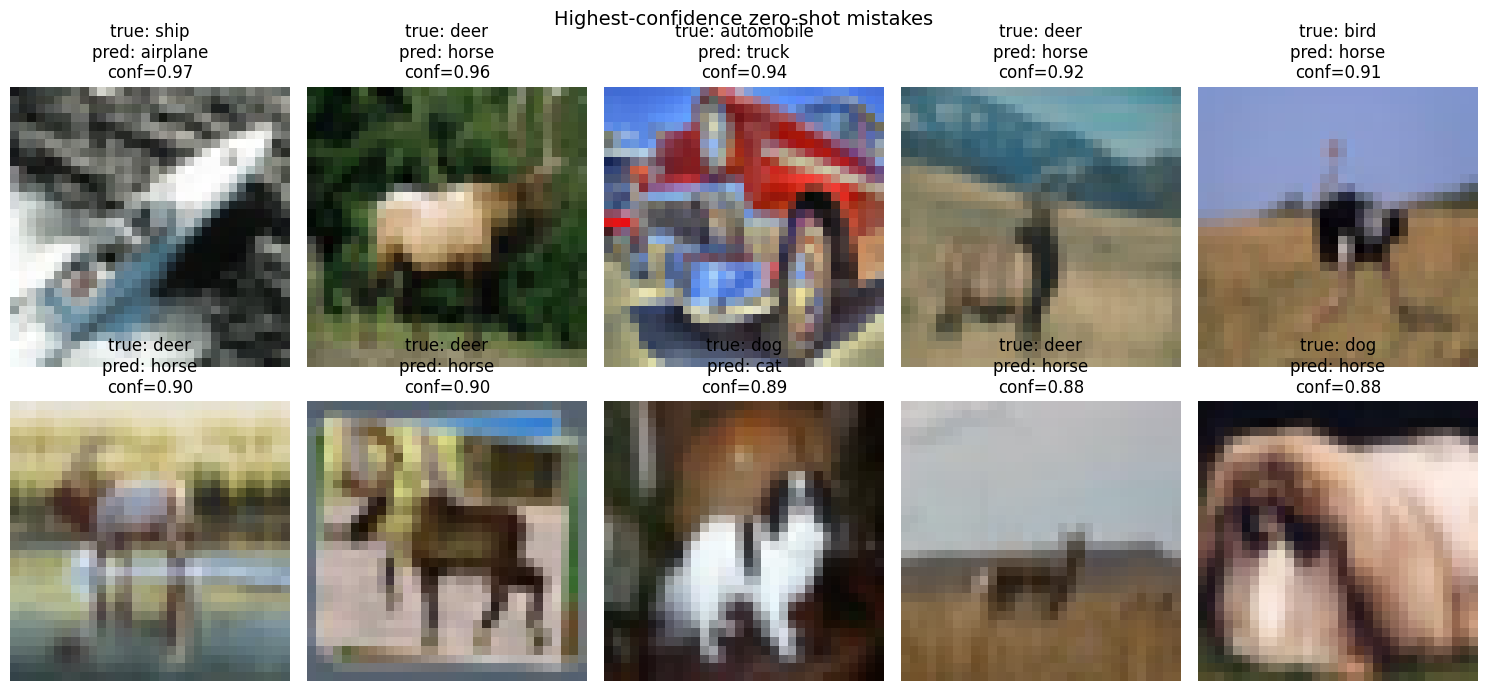

STEP 13: PASS — classification errors inspected


In [13]:
mistakes_df = (
    predictions_df.loc[~predictions_df["correct"]]
    .sort_values("confidence", ascending=False)
    .head(10)
    .copy()
)
mistakes_df.to_csv(OUTPUT_DIR / "highest_confidence_mistakes.csv", index=False)

if len(mistakes_df):
    fig, axes = plt.subplots(2, 5, figsize=(15, 7))
    for axis, row in zip(axes.ravel(), mistakes_df.itertuples(index=False)):
        image, _ = cifar10[row.dataset_index]
        axis.imshow(image)
        axis.set_title(
            f"true: {row.true_class_name}\npred: {row.predicted_class_name}\nconf={row.confidence:.2f}"
        )
        axis.axis("off")
    for axis in axes.ravel()[len(mistakes_df):]:
        axis.axis("off")
    fig.suptitle("Highest-confidence zero-shot mistakes", fontsize=14)
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "highest_confidence_mistakes.png", dpi=180)
    plt.show()
else:
    print("No mistakes were found; the mistake figure was not needed.")

print("STEP 13: PASS — classification errors inspected")


## Step 14 — Generate measured findings

The final discussion below is assembled from this run's values. It does not contain placeholder claims about which class performed best or worst.


In [14]:
target_rank_by_mean = int(
    class_similarity_summary_df.reset_index(drop=True).index[
        class_similarity_summary_df["true_class_id"] == TARGET_CLASS_ID
    ][0]
) + 1
similarity_gap = target_mean - non_target_mean

findings = [
    f"1. **Caption similarity:** the caption `{CAPTION}` was compared with {len(similarity_df):,} images, including exactly {IMAGES_PER_CLASS} from every CIFAR-10 class.",
    f"2. **Class alignment:** `{TARGET_CLASS_NAME}` ranked {target_rank_by_mean} of {NUM_CLASSES} by mean cosine similarity. Its mean was {target_mean:.4f}, compared with {non_target_mean:.4f} across non-target images (gap {similarity_gap:+.4f}).",
    f"3. **Top matches:** {top_20_target_fraction:.0%} of the 20 highest-scoring images belonged to the target class. The highest mean-similarity class was `{highest_mean_class}`.",
    f"4. **Zero-shot accuracy:** CLIP classified the balanced 1,000-image subset with overall accuracy {overall_accuracy:.2%}, without CIFAR-10 training or fine-tuning.",
    f"5. **Class variation:** the best class was `{best_class_row['class_name']}` at {best_class_row['accuracy']:.2%}; the lowest was `{worst_class_row['class_name']}` at {worst_class_row['accuracy']:.2%}.",
    f"6. **Largest confusion:** the most frequent off-diagonal error was {largest_confusion}.",
    "7. **Interpretation:** CLIP transfers useful semantic knowledge to CIFAR-10, but the 32×32 images are much lower resolution than typical CLIP training images. Similar-looking classes and prompt wording therefore still affect the results.",
]

display(Markdown("## Final findings\n\n" + "\n\n".join(findings)))
print("STEP 14: PASS — findings generated from measured results")


## Final findings

1. **Caption similarity:** the caption `a clear color photograph of a car` was compared with 1,000 images, including exactly 100 from every CIFAR-10 class.

2. **Class alignment:** `automobile` ranked 1 of 10 by mean cosine similarity. Its mean was 0.2518, compared with 0.1943 across non-target images (gap +0.0576).

3. **Top matches:** 100% of the 20 highest-scoring images belonged to the target class. The highest mean-similarity class was `automobile`.

4. **Zero-shot accuracy:** CLIP classified the balanced 1,000-image subset with overall accuracy 89.50%, without CIFAR-10 training or fine-tuning.

5. **Class variation:** the best class was `horse` at 98.00%; the lowest was `frog` at 76.00%.

6. **Largest confusion:** the most frequent off-diagonal error was deer → horse (18 of 100 images).

7. **Interpretation:** CLIP transfers useful semantic knowledge to CIFAR-10, but the 32×32 images are much lower resolution than typical CLIP training images. Similar-looking classes and prompt wording therefore still affect the results.

STEP 14: PASS — findings generated from measured results


## Step 15 — Export the final submission evidence

This cell creates the report-style Markdown files, configuration, environment record, run log, and manifest used in the previous homework submissions.


In [15]:
run_config = {
    "student": STUDENT,
    "SID4": SID4,
    "seed": SEED,
    "dataset": "torchvision.datasets.CIFAR10",
    "split": "test",
    "classes": CLASS_NAMES,
    "images_per_class": IMAGES_PER_CLASS,
    "total_images": len(selected_df),
    "selection": "seeded sample without replacement within each class",
    "model": MODEL_NAME,
    "batch_size": BATCH_SIZE,
    "embedding_dimension": EMBEDDING_DIMENSION,
    "caption": CAPTION,
    "target_class_id": TARGET_CLASS_ID,
    "target_class_name": TARGET_CLASS_NAME,
    "zero_shot_templates": PROMPT_TEMPLATES,
    "fine_tuning": False,
}
(OUTPUT_DIR / "run_config.json").write_text(json.dumps(run_config, indent=2), encoding="utf-8")

environment = {
    "python": platform.python_version(),
    "platform": platform.platform(),
    "torch": torch.__version__,
    "torchvision": torchvision.__version__,
    "transformers": transformers.__version__,
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "scikit_learn": sklearn.__version__,
    "cuda_available": torch.cuda.is_available(),
    "cuda_version": torch.version.cuda,
    "device": str(DEVICE),
    "hardware": GPU_NAME,
}
(OUTPUT_DIR / "environment.json").write_text(json.dumps(environment, indent=2), encoding="utf-8")

metrics_summary = {
    "caption": CAPTION,
    "caption_target_class": TARGET_CLASS_NAME,
    "target_class_mean_similarity": target_mean,
    "non_target_mean_similarity": non_target_mean,
    "target_vs_non_target_gap": similarity_gap,
    "target_class_rank_by_mean_similarity": target_rank_by_mean,
    "target_fraction_among_top_20": top_20_target_fraction,
    "zero_shot_overall_accuracy": overall_accuracy,
    "best_class": str(best_class_row["class_name"]),
    "best_class_accuracy": float(best_class_row["accuracy"]),
    "worst_class": str(worst_class_row["class_name"]),
    "worst_class_accuracy": float(worst_class_row["accuracy"]),
    "largest_confusion": largest_confusion,
    "image_embedding_seconds": embedding_seconds,
}
(OUTPUT_DIR / "metrics_summary.json").write_text(
    json.dumps(metrics_summary, indent=2), encoding="utf-8"
)

similarity_md_table = class_similarity_summary_df.copy()
for column in ["mean_similarity", "std_similarity", "min_similarity", "median_similarity", "max_similarity"]:
    similarity_md_table[column] = similarity_md_table[column].map(lambda value: f"{value:.4f}")

accuracy_md_table = per_class_accuracy_df.copy()
accuracy_md_table["accuracy"] = accuracy_md_table["accuracy"].map(lambda value: f"{value:.2%}")

metrics_md = f'''# Homework 11 Metrics

Student: {STUDENT}
SID4: {SID4}
Model: `{MODEL_NAME}`
Dataset: CIFAR-10 test split; {IMAGES_PER_CLASS} images per class; {len(selected_df):,} images total

## Caption-to-image similarity

Caption: `{CAPTION}`
Target class: `{TARGET_CLASS_NAME}`

{similarity_md_table.to_markdown(index=False)}

## Zero-shot classification

Overall accuracy: **{overall_accuracy:.2%}**

{accuracy_md_table.to_markdown(index=False)}

The raw and normalized confusion matrices are saved in `confusion_matrix_counts.csv` and `confusion_matrix_normalized.csv`.
'''
(OUTPUT_DIR / "METRICS.md").write_text(metrics_md, encoding="utf-8")

findings_md = f'''# Homework 11 Findings

## Method

I selected exactly {IMAGES_PER_CLASS} CIFAR-10 test images from each class with seed {SEED}. I used `{MODEL_NAME}` without fine-tuning. Image and text features were L2-normalized, so their dot products are cosine similarities. For classification, five text prompts per class were averaged into one normalized prototype.

## Results and interpretation

{chr(10).join(findings)}

## Limitations

- This is a balanced 1,000-image sample rather than the complete 10,000-image CIFAR-10 test set.
- CIFAR-10 images are only 32×32 pixels and must be resized for CLIP.
- Zero-shot results depend on the wording of the class prompts.
- Similarity indicates semantic alignment; it is not a calibrated probability that the caption is literally correct.
'''
(OUTPUT_DIR / "FINDINGS.md").write_text(findings_md, encoding="utf-8")

ai_use_md = '''# AI Use — Homework 11

I used an AI assistant to develop the first-cut experiment structure, convert the assignment requirements into separate similarity and zero-shot classification sections, and understand how normalized CLIP embeddings produce cosine similarity. I also used it to develop and execute the idea for balanced sampling, prompt ensembling, reproducibility checks, and result export.

I reviewed the demo's single-image FashionMNIST example and expanded it to the required CIFAR-10 experiment with 100 images per class. I ran the complete notebook, inspected the similarity plots, per-class accuracy, confusion matrix, and saved tables, and used those measured outputs for the final findings. The final execution, verification, and interpretation are my responsibility.
'''
(OUTPUT_DIR / "AI_USE.md").write_text(ai_use_md, encoding="utf-8")

readme_md = f'''# DATA 266 Homework 11 — CLIP on CIFAR-10

Student: {STUDENT}
SID4: {SID4}

This submission uses CLIP to compare one caption with 1,000 balanced CIFAR-10 images and to perform zero-shot classification on the same set.

## Main files

- `HW11_CLIP_CIFAR10_Nikhil_Kanaparthi_6441.ipynb`: executed notebook; download it separately from Colab and place it in the `HW11/` folder.
- `METRICS.md`: similarity statistics and per-class classification accuracy.
- `FINDINGS.md`: measured findings and limitations.
- `AI_USE.md`: AI-use disclosure.
- `caption_image_similarity_scores.csv`: all 1,000 caption–image cosine similarities.
- `caption_similarity_by_class.csv`: similarity summaries for all 10 classes.
- `zero_shot_predictions.csv`: image-level predictions and confidence values.
- `per_class_accuracy.csv`: required per-class accuracy.
- `confusion_matrix_counts.csv` and `confusion_matrix_normalized.csv`: required confusion matrix data.
- `figures/`: scored image grids, similarity plot, per-class accuracy, confusion matrix, and mistakes.
- `run_config.json`, `environment.json`, `metrics_summary.json`, `RUN_LOG.txt`: reproducibility evidence.

## Reproduce

Open the notebook in Google Colab, select a GPU runtime if available, and use **Runtime → Run all**. No API key is needed. The last cell creates `HW11_outputs.zip`.

## Repository submission

Extract the ZIP into `data266-6441/HW11/`, add the executed notebook, make progressive commits, push `main`, create the annotated tag `hw11`, and submit the GitHub release or tag URL requested by Canvas.
'''
(OUTPUT_DIR / "README.md").write_text(readme_md, encoding="utf-8")

requirements_text = '''transformers>=4.45,<5
scikit-learn>=1.4
pandas>=2.0
matplotlib>=3.8
seaborn>=0.13
tabulate>=0.9
'''
(OUTPUT_DIR / "requirements.txt").write_text(requirements_text, encoding="utf-8")

log("Saved final metrics, findings, AI-use statement, and reproducibility metadata")
RUN_LOG_LINES.append("\nMETRICS SUMMARY")
RUN_LOG_LINES.append(json.dumps(metrics_summary, sort_keys=True))
RUN_LOG_LINES.append("\nPER-CLASS ACCURACY")
RUN_LOG_LINES.extend(per_class_accuracy_df.to_json(orient="records", lines=True).splitlines())
(OUTPUT_DIR / "RUN_LOG.txt").write_text("\n".join(RUN_LOG_LINES) + "\n", encoding="utf-8")

expected_files = [
    "README.md", "FINDINGS.md", "METRICS.md", "AI_USE.md", "RUN_LOG.txt",
    "requirements.txt", "run_config.json", "environment.json", "metrics_summary.json",
    "selected_image_manifest.csv", "caption_image_similarity_scores.csv",
    "caption_similarity_by_class.csv", "zero_shot_prompts.csv",
    "zero_shot_predictions.csv", "classification_report.csv", "per_class_accuracy.csv",
    "confusion_matrix_counts.csv", "confusion_matrix_normalized.csv",
    "highest_confidence_mistakes.csv",
    "figures/caption_similarity_distributions.png",
    "figures/best_image_per_class_with_scores.png",
    "figures/top_10_caption_matches.png",
    "figures/per_class_accuracy.png",
    "figures/confusion_matrix_normalized.png",
]
if len(mistakes_df):
    expected_files.append("figures/highest_confidence_mistakes.png")

missing = [name for name in expected_files if not (OUTPUT_DIR / name).exists()]
assert not missing, f"Missing required artifacts: {missing}"
(OUTPUT_DIR / "submission_manifest.txt").write_text(
    "\n".join(expected_files + ["submission_manifest.txt"]) + "\n", encoding="utf-8"
)

print("Created files:")
for path in sorted(OUTPUT_DIR.rglob("*")):
    if path.is_file():
        print(f" - {path.relative_to(OUTPUT_DIR)} ({path.stat().st_size / 1024:.1f} KiB)")
print("STEP 15: PASS — submission documentation created")


[2026-11-17T22:33:21.900031+00:00] Saved final metrics, findings, AI-use statement, and reproducibility metadata
Created files:
 - AI_USE.md (0.8 KiB)
 - FINDINGS.md (1.8 KiB)
 - METRICS.md (3.0 KiB)
 - README.md (1.5 KiB)
 - RUN_LOG.txt (2.5 KiB)
 - caption_image_similarity_scores.csv (69.8 KiB)
 - caption_similarity_by_class.csv (0.9 KiB)
 - classification_report.csv (0.7 KiB)
 - confusion_matrix_counts.csv (0.3 KiB)
 - confusion_matrix_normalized.csv (0.6 KiB)
 - environment.json (0.3 KiB)
 - figures/best_image_per_class_with_scores.png (108.7 KiB)
 - figures/caption_similarity_distributions.png (91.0 KiB)
 - figures/confusion_matrix_normalized.png (151.7 KiB)
 - figures/highest_confidence_mistakes.png (122.7 KiB)
 - figures/per_class_accuracy.png (80.0 KiB)
 - figures/top_10_caption_matches.png (119.1 KiB)
 - highest_confidence_mistakes.csv (0.5 KiB)
 - metrics_summary.json (0.6 KiB)
 - per_class_accuracy.csv (0.2 KiB)
 - requirements.txt (0.1 KiB)
 - run_config.json (0.8 KiB)
 - s

## Step 16 — Final validation and ZIP download

The checks below verify the sample size, balanced class counts, normalized embeddings, image-level predictions, per-class metrics, and confusion matrix before creating the ZIP. Also download the executed notebook from Colab using **File → Download → Download .ipynb**.


In [16]:
assert len(selected_df) == 1000
assert selected_df.groupby("true_class_id").size().eq(100).all()
assert len(similarity_df) == 1000 and similarity_df["cosine_similarity"].notna().all()
assert len(predictions_df) == 1000 and predictions_df["predicted_class_id"].between(0, 9).all()
assert len(per_class_accuracy_df) == 10
assert cm_counts.shape == (10, 10) and np.all(cm_counts.sum(axis=1) == 100)
assert 0.0 <= overall_accuracy <= 1.0

if ZIP_PATH.exists():
    ZIP_PATH.unlink()
shutil.make_archive(str(ZIP_PATH.with_suffix("")), "zip", root_dir=OUTPUT_DIR)
assert ZIP_PATH.exists() and ZIP_PATH.stat().st_size > 0

print("=" * 76)
print("HW11 FINAL VALIDATION: PASS")
print("Images evaluated:", len(selected_df))
print("Images per class:", IMAGES_PER_CLASS)
print(f"Overall zero-shot accuracy: {overall_accuracy:.2%}")
print("ZIP:", ZIP_PATH)
print(f"ZIP size: {ZIP_PATH.stat().st_size / (1024**2):.2f} MiB")
print("=" * 76)
print("Download this ZIP and the executed notebook. Put both contents in your repository's HW11 folder.")

try:
    from google.colab import files
    files.download(str(ZIP_PATH))
except Exception as exc:
    print("Automatic download is unavailable here; use the Files panel:", exc)


HW11 FINAL VALIDATION: PASS
Images evaluated: 1000
Images per class: 100
Overall zero-shot accuracy: 89.50%
ZIP: /content/HW11_outputs.zip
ZIP size: 0.58 MiB
Download this ZIP and the executed notebook. Put both contents in your repository's HW11 folder.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>